# Think Bayes & Statistical Rethinking — Chapter 16: Laplace / Quadratic Approximation
> *Reference: Paraphrased from Richard McElreath's Statistical Rethinking (Chapter 4) and Allen Downey's Think Bayes (Chapter 15).*

While grid approximation is exact for low-dimensional models, parameter dimensions above $d=2$ quickly suffer from the curse of dimensionality.
The **Laplace (or Quadratic) Approximation** (`LaplaceApproximation`, aliased as `QuadraticApproximation` and `Quap`)
finds the Maximum A Posteriori (MAP) estimate $\hat{\theta}$ and inverts the negative Hessian matrix $\mathbf{H}^{-1}$ to construct
a Gaussian approximation to the joint posterior distribution:
$$\theta \mid D \approx \mathcal{N}(\hat{\theta}, \mathbf{H}^{-1})$$
This notebook demonstrates:
1. **Continuous Normal Likelihood** for adult human heights.
2. **MAP Optimization & Numerical Hessian Inversion**.
3. **Marginal Posterior Extraction** as exact `Normal` distributions.
4. **Posterior Sampling & Forest Plot Visualizations**.

In [1]:
import set_paths
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from make_data import load_heights
from probability.distributions import Normal, MVNormal
from probability.models import LaplaceApproximation, Quap

## 16.1 Adult Heights Dataset
We load human adult height measurements and filter to adults (age $\ge 18$).

In [2]:
heights_df = load_heights()
adults = heights_df[heights_df['age'] >= 18]['height'].values
print(f"Number of adult observations: {len(adults)}")
print(f"Sample Mean: {np.mean(adults):.2f} cm, Sample SD: {np.std(adults, ddof=1):.2f} cm")

Number of adult observations: 200
Sample Mean: 174.69 cm, Sample SD: 6.98 cm


## 16.2 Specifying the Log-Posterior
We model heights as $h_i \sim \mathcal{N}(\mu, \sigma)$ with weakly informative priors:
- $\mu \sim \mathcal{N}(178, 20)$
- $\sigma \sim \text{Uniform}(0.1, 50)$

In [3]:
def log_prior(mu, sigma):
    if sigma <= 0.1 or sigma >= 50.0:
        return -np.inf
    log_p_mu = -0.5 * ((mu - 178.0) / 20.0) ** 2
    log_p_sigma = -np.log(50.0 - 0.1)
    return log_p_mu + log_p_sigma

def log_likelihood(mu, sigma, data):
    n = len(data)
    return -0.5 * n * np.log(2.0 * np.pi * sigma ** 2) - np.sum((data - mu) ** 2) / (2.0 * sigma ** 2)

def log_post(theta):
    mu, sigma = theta[0], theta[1]
    lp = log_prior(mu, sigma)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(mu, sigma, adults)

## 16.3 Fitting the Quadratic Approximation (`Quap`)
We fit the quadratic approximation via `LaplaceApproximation.fit()`.

In [4]:
quap_model = LaplaceApproximation.fit(
    log_posterior_fn=log_post,
    start_params={'mu': 175.0, 'sigma': 10.0},
    bounds={'mu': (120.0, 220.0), 'sigma': (0.5, 30.0)}
)
print('--- Laplace Approximation Summary Table ---')
quap_model.summary(hdi=0.95).round(4)

--- Laplace Approximation Summary Table ---


,mean,std,95% HDI lower,95% HDI upper
mu,174.6962,0.4924,173.7312,175.6612
sigma,6.9651,0.3483,6.2825,7.6476


## 16.4 Marginal Posterior Distributions
The model provides analytical `Normal` distributions for each parameter's marginal posterior.

In [5]:
mu_norm = quap_model.marginal('mu')
sigma_norm = quap_model.marginal('sigma')

print(f"mu posterior:    Normal(mu={mu_norm.mu:.3f}, sigma={mu_norm.sigma:.3f})")
print(f"mu 95% HDI:      {mu_norm.interval(0.95)}")
print(f"sigma posterior: Normal(mu={sigma_norm.mu:.3f}, sigma={sigma_norm.sigma:.3f})")
print(f"sigma 95% HDI:   {sigma_norm.interval(0.95)}")

mu posterior:    Normal(mu=174.696, sigma=0.492)
mu 95% HDI:      (np.float64(173.73122452252522), np.float64(175.66121848941287))
sigma posterior: Normal(mu=6.965, sigma=0.348)
sigma 95% HDI:   (np.float64(6.282490549181893), np.float64(7.647616711158395))


## 16.5 Posterior Sampling & Visualizations
We can draw samples from the joint Gaussian posterior and render forest and marginal density plots.

In [6]:
samples = quap_model.sample(n=2000, seed=42)
print(f"Drawn {len(samples)} posterior samples:")
samples.head()

Drawn 2000 posterior samples:


,mu,sigma
0,174.451690,6.916762
1,174.377024,7.495269
2,174.811555,6.883581
3,173.918535,7.231867
4,174.927261,7.154135


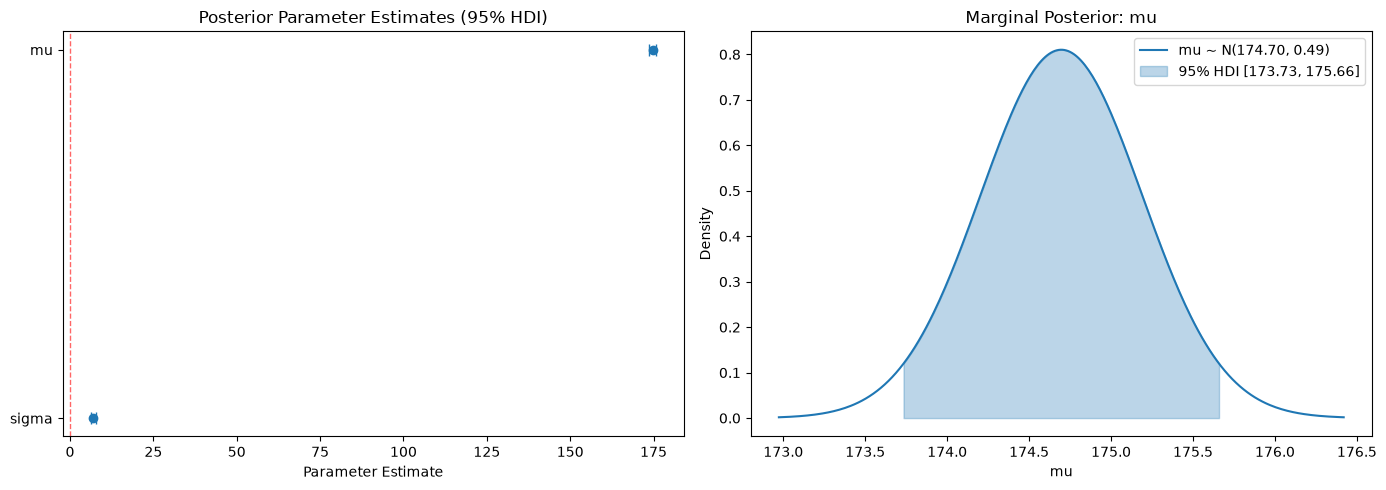

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

quap_model.plot_forest(
    hdi=0.95,
    ax=axes[0],
    title="Posterior Parameter Estimates (95% HDI)"
)

quap_model.plot_marginal(
    param='mu',
    hdi=0.95,
    ax=axes[1]
)

plt.tight_layout()